# First Passage Percolation

Consideramos el grafo con conjunto de vértices $\mathbb{Z}^d$ y conjunto de aristas $\mathcal{E}^d:=\{uv : |u-v|_1=1\}$, que denotaremos simplemente por $\mathbb{Z}^d$. Consideramos también una medida de probabilidad $\nu$ con función de distribución $F$ sobre $[0,\infty)$. Colocamos una variable aleatoria $\omega_e$ en cada arista $e\in\mathcal{E}^d$, que llamamos el *tiempo de pasada de la arista*. Asumimos que $(\omega_e)_{e\in\mathcal{E}_d} \overset{\textrm{iid}}{\sim} \nu$, y llamamos a $(\omega_e)_{e\in\mathcal{E}_d}$ el *entorno*.

Un *camino* en $\mathbb{Z}^d$ es una secuencia de aristas de la forma $\gamma = v_0v_1, v_1v_2, ..., v_{n-1}v_n$, donde $v_i\in \mathbb{Z}^d$. En el caso anterior, escribimos $v_iv_{i+1}\in\gamma$ y (abusando de la notación) $v_i\in \gamma$. También decimos que $\gamma$ es un *camino de* $v_1$ *a* $v_n$, y escribimos $\gamma:v_1\to v_n$. Denotamos el número de aristas de $\gamma$ como $\#\gamma$. Notar que un camino puede repetir aristas o vértices. Si no lo hace, decimos que es un *camino autoevitante*. 

Dado un camino $\gamma$, definimos su *tiempo de pasada* como la variable aleatoria
$$T(\gamma) := \sum_{e\in \gamma} \omega_e \: ,$$
y definimos el *tiempo de pasada entre dos vértices* $u$ y $v$ como la variable aleatoria
$$T(u,v) := \inf\{T(\gamma) \: | \: \gamma: u\to v\}.$$
Notar que, como los pesos son no negativos, el valor de $T(u,v)$ no cambia si tomamos el ínfimo sobre los caminos autoevitantes de $u$ a $v$. 

$T(\cdot, \cdot)$ cumple todas las propiedades de una función de distancia, salvo que podemos tener $T(u, v) = 0$ para $u\neq v$, lo que convierte a $T(\cdot, \cdot)$ en una *pseudodistancia*. El grafo $\mathbb{Z}^d$ dotado de esta pseudodistancia aleatoria constituye el modelo de *Percolación de Primera Pasada*.

Si $F(0) = \mathbb{P}(\omega_e = 0)$ es menor que el threshold de bond-percolation $p_c(d)$, entonces casi seguramente existen *geodésicas*, esto es, caminos que minimizan el tiempo de pasada, entre cualquiera dos puntos. Si la distribución de pesos de las aristas es absolutamente continua, entonces casi seguramente existe una *única* geodésica entre cualquiera dos puntos.

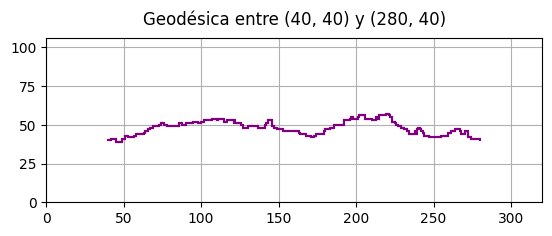

In [7]:
from utils import dijkstra, fpp, reconstruir_geo, grid_canvas
from random import expovariate
import matplotlib.pyplot as plt
import numpy as np

n = 320
dims = (n, int(n / 3))
inicio = (int(n / 8), int(n / 8))
final = (int(7 * n / 8), int(n / 8))

pesos = fpp(*dims, lambda: expovariate(1))
dists, ancest = dijkstra(*dims, pesos, inicio)
    
geo = reconstruir_geo(inicio, final, ancest)
grid_canvas(*dims, [], geo, 'purple', 'Geodésica entre (40, 40) y (280, 40)')

/var/folders/v7/3kltkyvd3lx4p1_9zy_69f7w0000gn/T/ipykernel_2017/1680060403.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


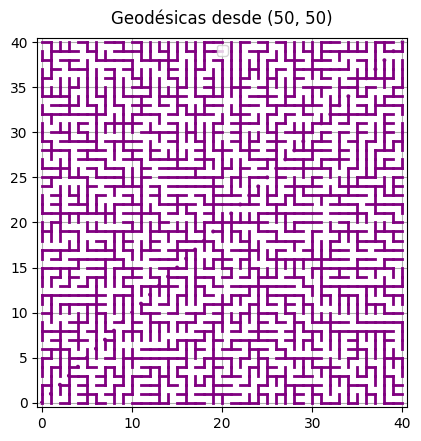

In [11]:
n = 40
m = int(n / 2)
x = np.linspace(0, n, n + 1)
y = x

plt.scatter(x, y, c='purple', s=8, alpha=1, edgecolors='none')

plt.xlim(- 0.5, n + 0.5)
plt.ylim(- 0.5, n + 0.5)
plt.legend()
plt.grid(True)
plt.gca().set_aspect('equal')

environment = fpp(n, n, lambda: expovariate(1))
dists, ancestros = dijkstra(n, n, environment, (m, m))

for a in range(n + 1):
    for b in range(n + 1):

        if a == m and b == m:
            continue

        ancestro = ancestros[a, b]
        plt.plot((a, ancestro[0]), (b, ancestro[1]), color='purple', lw=2)

plt.title("Geodésicas desde (50, 50)", pad=10)
plt.show()